# TP2 KASDAD - Klasifikasi `artifact_signal`

**EDA individual:** Apakah persentase laporan berlabel `artifact_signal = 1` berbeda antara `signal_stream` kosong dan terisi, setelah mempertimbangkan waktu dan volume laporan?

C4_HGB memakai hybrid structured + TF-IDF Logistic Regression saat teks terisi, dan structured HGB saat kosong. Metrik utama: **Macro F1**.

**Identitas:** Kelompok **A06 - KasdudLovers** | **Samuel Indriano** | NPM **2406400524**.

Notebook mencakup data, EDA, preprocessing, pemodelan, dan evaluasi temporal. Approach individual ini berbeda dari ensemble champion kelompok terbaru.

## 1. Persiapan

Gunakan dependencies dan lokasi data di [README](README.md), lalu Restart & Run All. Refit penuh tetap dimatikan secara default.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "src" / "models").is_dir() and (candidate / "notebooks" / "samuel").is_dir():
            return candidate
    raise FileNotFoundError(
        "Folder repository KASDAD tidak ditemukan. Buka notebook dari dalam repository."
    )

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.paths import task_files
from src.models.classification_models import _array_digest
from src.models.classification_round2_models import build_round2_model, stream_missing_mask
from src.models.classification_round2_metrics import binary_metrics

# Some reporting modules select Agg at import time. Set the notebook
# display backend only after all project imports have completed.
get_ipython().run_line_magic("matplotlib", "inline")

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})
print("Repository:", PROJECT_ROOT)
print("Dataset default: data/raw/classification/ | Override: TP2_DATA_DIR ke root data/ yang berisi classification/")

Repository: C:\Users\Sam\OneDrive\Documents\KASDAD\TP 2
Dataset default: data/raw/classification/ | Override: TP2_DATA_DIR ke root data/ yang berisi classification/


## 2. Dataset dan target

Label 1 berarti indikasi artefak eksploit publik teramati; label 0 tidak memastikan artefak tidak ada. Train mencakup cycle 47-79, Test 80-91. Validasi mengikuti waktu dan seluruh preprocessing dipelajari dari data fit.

Macro F1 memberi bobot sama pada F1 kedua kelas. Recipe TP1 dievaluasi ulang karena target TP2 berbeda.

In [2]:
DATA_FILES = task_files("classification")
if DATA_FILES["train"] is None:
    raise FileNotFoundError(
        "Train.csv tidak ditemukan. Letakkan di data/raw/classification/ atau atur TP2_DATA_DIR ke direktori induk data."
    )

train_path = DATA_FILES["train"]
train = pd.read_csv(train_path)
required = {"artifact_signal", "cycle_code", "signal_stream", "entry_friction", "impact_load"}
missing_columns = sorted(required - set(train.columns))
assert not missing_columns, f"Kolom Train yang diperlukan tidak ada: {missing_columns}"
assert train["artifact_signal"].notna().all()
assert set(train["artifact_signal"].unique()) == {0, 1}
assert train["cycle_code"].between(47, 79).all()

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

r1_freeze = json.loads((PROJECT_ROOT / "experiments/classification_round1/freeze.json").read_text(encoding="utf-8"))
r2_freeze = json.loads((PROJECT_ROOT / "experiments/classification_round2/freeze.json").read_text(encoding="utf-8"))
actual_train_sha256 = sha256_file(train_path)
expected_train_sha256 = r1_freeze["identity"]["input_sha256"]["train"]
assert actual_train_sha256 == expected_train_sha256, "Train bytes differ from the frozen classification input."
assert r2_freeze["identity"]["round1_freeze_signature"] == r1_freeze["signature"]

def normalized_source_sha256(relative_path):
    source = (PROJECT_ROOT / relative_path).read_bytes().replace(b"\r\n", b"\n")
    return hashlib.sha256(source).hexdigest()

required_source_refs = {
    "src/models/classification_models.py": r1_freeze["identity"]["code_sha256"],
    "src/models/round1_models.py": r1_freeze["identity"]["code_sha256"],
    "src/models/classification_round2_models.py": r2_freeze["identity"]["new_code_sha256"],
    "src/models/classification_round2_metrics.py": r2_freeze["identity"]["new_code_sha256"],
}
source_checks = []
for relative_path, frozen_map in required_source_refs.items():
    observed = normalized_source_sha256(relative_path)
    expected = frozen_map[relative_path]
    source_checks.append({"source": relative_path, "matches frozen source": observed == expected})
assert all(row["matches frozen source"] for row in source_checks), "A model source file differs from its experiment freeze."
display(pd.DataFrame(source_checks))

positive_count = int(train["artifact_signal"].sum())
overview = pd.DataFrame([
    {"Train rows": len(train), "feature columns": len(train.columns) - 1,
     "cycles": f"{train.cycle_code.min()}–{train.cycle_code.max()}",
     "class 0": int((train.artifact_signal == 0).sum()), "class 1": positive_count,
     "prevalence class 1": positive_count / len(train),
     "signal_stream kosong": int(stream_missing_mask(train[["signal_stream"]]).sum()),
     "stream kosong (%)": float(stream_missing_mask(train[["signal_stream"]]).mean())}
])
display(overview.style.format({"prevalence class 1": "{:.2%}", "stream kosong (%)": "{:.2%}"}))
print("SHA-256 Train:", actual_train_sha256)

,source,matches frozen source
0,src/models/classification_models.py,True
1,src/models/round1_models.py,True
2,src/models/classification_round2_models.py,True
3,src/models/classification_round2_metrics.py,True


,Train rows,feature columns,cycles,class 0,class 1,prevalence class 1,signal_stream kosong,stream kosong (%)
0,50608,18,47–79,33038,17570,34.72%,3404,6.73%


SHA-256 Train: 875552a68a3d24b0f3e1966d6ddb5671e6f54305a1c526e2f0a76747942ed91c


### Label per cycle

Perubahan proporsi label mendukung penggunaan validasi temporal.

,awal_rows,awal_positive_rate,akhir_rows,akhir_positive_rate
cycle_code,,,,
47,1342.0,0.273472,NaN,NaN
48,977.0,0.384852,NaN,NaN
49,1255.0,0.239044,NaN,NaN
77,NaN,NaN,2335.0,0.285225
78,NaN,NaN,2146.0,0.250233
79,NaN,NaN,2188.0,0.307587


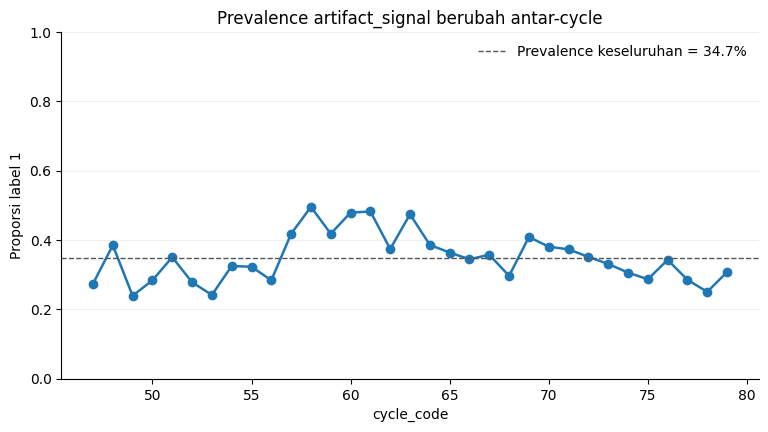

In [3]:
cycle_summary = (
    train.groupby("cycle_code", as_index=False)
    .agg(rows=("artifact_signal", "size"), positive_rate=("artifact_signal", "mean"))
)
fig, ax = plt.subplots()
ax.plot(cycle_summary.cycle_code, cycle_summary.positive_rate, marker="o", linewidth=1.8, color="#1f77b4")
ax.axhline(train.artifact_signal.mean(), color="#555555", linestyle="--", linewidth=1,
           label=f"Prevalence keseluruhan = {train.artifact_signal.mean():.1%}")
ax.set(title="Prevalence artifact_signal berubah antar-cycle", xlabel="cycle_code", ylabel="Proporsi label 1")
ax.set_ylim(0, 1)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
early_cycles = cycle_summary.head(3).set_index("cycle_code").add_prefix("awal_")
late_cycles = cycle_summary.tail(3).set_index("cycle_code").add_prefix("akhir_")
display(pd.concat([early_cycles, late_cycles], axis=1))
plt.show()

## 3. EDA individual: teks kosong dan terisi

**Apakah persentase laporan berlabel `artifact_signal = 1` berbeda antara `signal_stream` kosong dan terisi, setelah mempertimbangkan waktu dan volume laporan?**

Sumber: official Classification Train.

### EDA 1. Data dan metode

Teks **kosong** berarti null, string kosong, atau hanya spasi. Waktu memakai `cycle_code`; volume memakai `text_load`, bukan jumlah token.

Perbandingan disesuaikan dengan memberi bobot yang sama pada kelompok waktu/volume untuk kedua status. Bobot mengikuti jumlah baris pada kelompok yang didukung. Minimum **20 baris per status per kelompok**. Rentang volume memakai kuantil tanpa label; ini penyesuaian kasar, bukan pencocokan nilai persis.

In [4]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
eda_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
eda_PROJECT_ROOT = next((eda_p for eda_p in eda_candidates if (eda_p / 'src' / 'utils' / 'paths.py').is_file()), None)
if eda_PROJECT_ROOT is None:
    raise FileNotFoundError('Jalankan notebook dari dalam repository TP2.')
sys.path.insert(0, str(eda_PROJECT_ROOT))
from src.eda.availability import add_global_quantile_bins, prepare_availability_frame, prevalence_table, standardized_contrast, wilson_interval
from src.models.classification_round2_models import stream_missing_mask
from src.utils.paths import task_files
eda_train_path = task_files('classification')['train']
if eda_train_path is None:
    raise FileNotFoundError('Letakkan official Classification Train.csv di data/raw/classification/ atau atur TP2_DATA_DIR ke folder induk data.')
eda_train = pd.read_csv(eda_train_path)
eda_analysis = prepare_availability_frame(eda_train, stream_missing_mask(eda_train))
assert len(eda_analysis) == len(eda_train)
assert set(eda_analysis['availability'].unique()) == {'present', 'missing'}
assert eda_analysis['cycle_code'].min() == 47 and eda_analysis['cycle_code'].max() == 79
eda_COLORS = {'present': '#1f4e79', 'missing': '#d17a22'}
plt.rcParams.update({'figure.dpi': 120, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 9, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'Sumber: official Classification Train.csv | {len(eda_train):,} baris × {eda_train.shape[1]} kolom | cycle {eda_analysis.cycle_code.min()}–{eda_analysis.cycle_code.max()}')

Sumber: official Classification Train.csv | 50,608 baris × 19 kolom | cycle 47–79


### EDA 2. Gambaran data

Jumlah laporan, label positif, dan volume menurut ketersediaan teks.

In [5]:
eda_grouped = prevalence_table(eda_analysis, ['availability']).set_index('availability').loc[['present', 'missing']]
eda_overview = pd.DataFrame({'Baris (n)': eda_grouped['n'].astype(int), 'artifact_signal = 1 (n)': eda_grouped['positive'].astype(int), 'Proporsi artifact (%)': eda_grouped['prevalence'] * 100, 'text_load median': eda_analysis.groupby('availability')['text_load'].median().loc[['present', 'missing']], 'text_load Q1': eda_analysis.groupby('availability')['text_load'].quantile(0.25).loc[['present', 'missing']], 'text_load Q3': eda_analysis.groupby('availability')['text_load'].quantile(0.75).loc[['present', 'missing']]})
eda_overview.index.name = 'Availability'
display(eda_overview.round(2))
print(f'Total Train {len(eda_analysis):,}; label positif {eda_analysis.artifact_signal.sum():,} ({eda_analysis.artifact_signal.mean():.2%}); cycle unik {eda_analysis.cycle_code.nunique()}.')

,Baris (n),artifact_signal = 1 (n),Proporsi artifact (%),text_load median,text_load Q1,text_load Q3
Availability,,,,,,
present,47204,16272,34.47,31.78,27.70,36.92
missing,3404,1298,38.13,21.81,20.55,23.79


Total Train 50,608; label positif 17,570 (34.72%); cycle unik 33.


**Insight data.** Teks kosong hanya mencakup 6,73% laporan. Ukuran kelompok yang jauh berbeda perlu diperhatikan saat membaca persentase dan ketidakpastiannya.

### EDA 3. Perbandingan awal

Bandingkan persentase label 1 pada seluruh laporan. Error bar adalah interval Wilson 95% masing-masing kelompok, bukan interval selisihnya.

,Ketersediaan,artifact_signal = 1 (n),Denominator (n),Proporsi (%),Wilson 95% bawah (%),Wilson 95% atas (%)
0,present,16272,47204,34.47,34.04,34.90
1,missing,1298,3404,38.13,36.51,39.78


Proporsi artifact pada Train adalah **34.47%** saat stream tersedia dan **38.13%** saat missing. Selisih missing − present adalah **+3.66 poin persentase (pp)**.

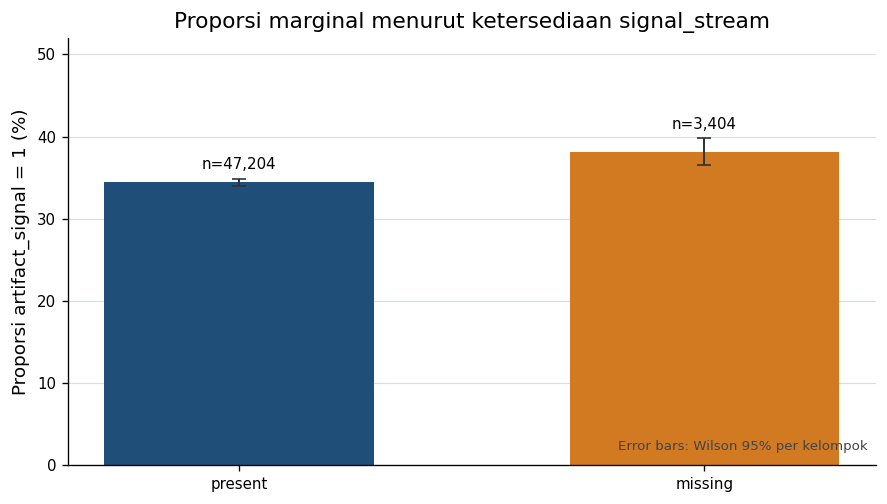

In [6]:
eda_marginal_rows = []
for eda_availability in ('present', 'missing'):
    eda_part = eda_analysis.loc[eda_analysis.availability.eq(eda_availability)]
    eda_successes, eda_n = (int(eda_part.artifact_signal.sum()), int(len(eda_part)))
    eda_low, eda_high = wilson_interval(eda_successes, eda_n)
    eda_marginal_rows.append({'Ketersediaan': eda_availability, 'artifact_signal = 1 (n)': eda_successes, 'Denominator (n)': eda_n, 'Proporsi (%)': 100 * eda_successes / eda_n, 'Wilson 95% bawah (%)': 100 * eda_low, 'Wilson 95% atas (%)': 100 * eda_high})
eda_marginal = pd.DataFrame(eda_marginal_rows)
eda_marginal_indexed = eda_marginal.set_index('Ketersediaan')
eda_marginal_gap_pp = eda_marginal_indexed.loc['missing', 'Proporsi (%)'] - eda_marginal_indexed.loc['present', 'Proporsi (%)']
display(eda_marginal.round(2))
display(Markdown(f"Proporsi artifact pada Train adalah **{eda_marginal_indexed.loc['present', 'Proporsi (%)']:.2f}%** saat stream tersedia dan **{eda_marginal_indexed.loc['missing', 'Proporsi (%)']:.2f}%** saat missing. Selisih missing − present adalah **{eda_marginal_gap_pp:+.2f} poin persentase (pp)**."))
eda_fig, eda_ax = plt.subplots(figsize=(7.5, 4.3))
eda_x = np.arange(len(eda_marginal))
eda_rates = eda_marginal['Proporsi (%)'].to_numpy()
eda_lower = eda_rates - eda_marginal['Wilson 95% bawah (%)'].to_numpy()
eda_upper = eda_marginal['Wilson 95% atas (%)'].to_numpy() - eda_rates
eda_ax.bar(eda_x, eda_rates, color=[eda_COLORS[eda_name] for eda_name in eda_marginal['Ketersediaan']], width=0.58, zorder=2)
eda_ax.errorbar(eda_x, eda_rates, yerr=np.vstack([eda_lower, eda_upper]), fmt='none', ecolor='#30343b', capsize=4, lw=1.2, zorder=3)
for eda_i, eda_row in eda_marginal.iterrows():
    eda_ax.text(eda_i, eda_row['Wilson 95% atas (%)'] + 1.2, f"n={int(eda_row['Denominator (n)']):,}", ha='center', fontsize=9)
eda_ax.set_xticks(eda_x, eda_marginal['Ketersediaan'])
eda_ax.set_ylabel('Proporsi artifact_signal = 1 (%)')
eda_ax.set_title('Proporsi marginal menurut ketersediaan signal_stream')
eda_ax.set_ylim(0, 52)
eda_ax.grid(axis='y', color='#d9dde3', linewidth=0.7, zorder=0)
eda_ax.text(0.99, 0.03, 'Error bars: Wilson 95% per kelompok', transform=eda_ax.transAxes, ha='right', va='bottom', fontsize=8, color='#40444b')
eda_fig.tight_layout()
plt.show()

**Insight perbandingan awal.** Label 1 lebih sering muncul pada kelompok kosong, dengan selisih +3,66 pp. Ini belum memperhitungkan perbedaan waktu dan volume laporan.

### EDA 4. Perubahan sepanjang waktu

Selisih kosong dikurangi terisi tidak positif pada semua cycle maupun periode.

,Present n,Present (%),Missing n,Missing (%),Gap missing − present (pp)
period,,,,,
47–57,12537,30.78,1009,28.94,-1.84
58–68,15664,40.37,1072,50.37,10.01
69–79,19003,32.05,1323,35.22,3.18


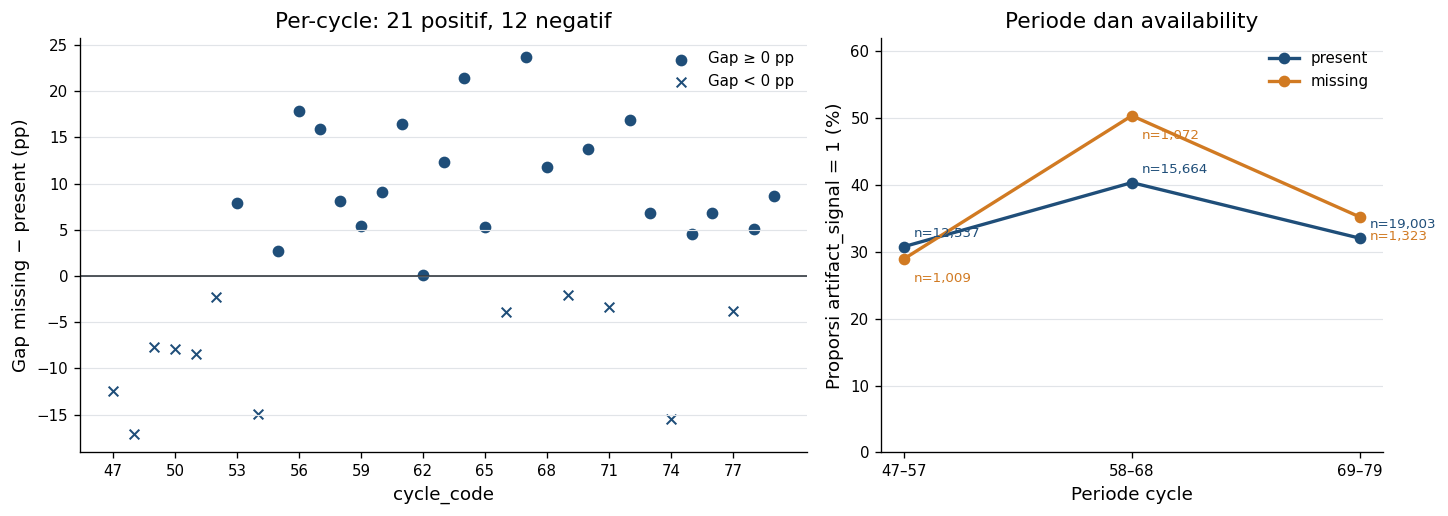

Gap per periode ialah **-1.84 pp**, **+10.01 pp**, dan **+3.18 pp**. Pada cycle dengan n≥20 untuk masing-masing status, 21/33 gap positif dan 12/33 negatif; rentangnya -17.04 sampai +23.73 pp.

In [7]:
eda_period_prevalence = prevalence_table(eda_analysis, ['period', 'availability'])
eda_period_pivot = eda_period_prevalence.pivot(index='period', columns='availability', values='prevalence').loc[['47–57', '58–68', '69–79']]
eda_period_n = eda_period_prevalence.pivot(index='period', columns='availability', values='n').loc[eda_period_pivot.index]
eda_period_summary = pd.DataFrame({'Present n': eda_period_n['present'].astype(int), 'Present (%)': 100 * eda_period_pivot['present'], 'Missing n': eda_period_n['missing'].astype(int), 'Missing (%)': 100 * eda_period_pivot['missing'], 'Gap missing − present (pp)': 100 * (eda_period_pivot['missing'] - eda_period_pivot['present'])})
display(eda_period_summary.round(2))
eda_cycle_prevalence = prevalence_table(eda_analysis, ['cycle_code', 'availability'])
eda_cycle_rates = eda_cycle_prevalence.pivot(index='cycle_code', columns='availability', values='prevalence')
eda_cycle_n = eda_cycle_prevalence.pivot(index='cycle_code', columns='availability', values='n')
eda_cycle_gap = 100 * (eda_cycle_rates['missing'] - eda_cycle_rates['present'])
eda_cycle_supported = eda_cycle_n['missing'].ge(20) & eda_cycle_n['present'].ge(20)
assert eda_cycle_supported.all(), 'Exact-cycle graph must not include unsupported groups'
eda_positive_cycles = int((eda_cycle_gap > 0).sum())
eda_negative_cycles = int((eda_cycle_gap < 0).sum())
eda_fig, (eda_ax_cycle, eda_ax_period) = plt.subplots(1, 2, figsize=(12.2, 4.4), gridspec_kw={'width_ratios': [1.45, 1]})
for eda_marker, eda_condition, eda_label in [('o', eda_cycle_gap >= 0, 'Gap ≥ 0 pp'), ('x', eda_cycle_gap < 0, 'Gap < 0 pp')]:
    eda_ax_cycle.scatter(eda_cycle_gap.index[eda_condition], eda_cycle_gap.loc[eda_condition], marker=eda_marker, s=34, color=eda_COLORS['present'], label=eda_label, linewidths=1.2)
eda_ax_cycle.axhline(0, color='#343a40', lw=1)
eda_ax_cycle.set_xticks(np.arange(47, 80, 3))
eda_ax_cycle.set_xlabel('cycle_code')
eda_ax_cycle.set_ylabel('Gap missing − present (pp)')
eda_ax_cycle.set_title(f'Per-cycle: {eda_positive_cycles} positif, {eda_negative_cycles} negatif')
eda_ax_cycle.legend(frameon=False, loc='best')
eda_ax_cycle.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_period_x = np.arange(len(eda_period_pivot))
for eda_availability in ('present', 'missing'):
    eda_values = 100 * eda_period_pivot[eda_availability].to_numpy()
    eda_ax_period.plot(eda_period_x, eda_values, marker='o', lw=2, color=eda_COLORS[eda_availability], label=eda_availability)
    for eda_j, (eda_value, eda_n) in enumerate(zip(eda_values, eda_period_n[eda_availability].to_numpy())):
        eda_offset = (6, 6) if eda_availability == 'present' else (6, -14)
        eda_ax_period.annotate(f'n={int(eda_n):,}', (eda_j, eda_value), xytext=eda_offset, textcoords='offset points', fontsize=8, color=eda_COLORS[eda_availability])
eda_ax_period.set_xticks(eda_period_x, eda_period_pivot.index)
eda_ax_period.set_xlabel('Periode cycle')
eda_ax_period.set_ylabel('Proporsi artifact_signal = 1 (%)')
eda_ax_period.set_title('Periode dan availability')
eda_ax_period.set_ylim(0, 62)
eda_ax_period.legend(frameon=False)
eda_ax_period.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_fig.tight_layout()
plt.show()
display(Markdown(f"Gap per periode ialah **{eda_period_summary.iloc[0]['Gap missing − present (pp)']:+.2f} pp**, **{eda_period_summary.iloc[1]['Gap missing − present (pp)']:+.2f} pp**, dan **{eda_period_summary.iloc[2]['Gap missing − present (pp)']:+.2f} pp**. Pada cycle dengan n≥20 untuk masing-masing status, {eda_positive_cycles}/{len(eda_cycle_gap)} gap positif dan {eda_negative_cycles}/{len(eda_cycle_gap)} negatif; rentangnya {eda_cycle_gap.min():+.2f} sampai {eda_cycle_gap.max():+.2f} pp."))

**Insight waktu.** Gap positif pada 21 dari 33 cycle, tetapi negatif pada 12 lainnya. Periode tengah menunjukkan perbedaan terbesar; satu angka agregat menyembunyikan variasi ini.

### EDA 5. Perbedaan volume

Histogram dinormalisasi agar ukuran kelompok yang berbeda tetap dapat dibandingkan. Distribusi volume kedua kelompok berbeda.

,n,minimum,q1,median,q3,maximum
availability,,,,,,
present,47204,20.65,27.70,31.78,36.92,98.06
missing,3404,16.34,20.55,21.81,23.79,77.52


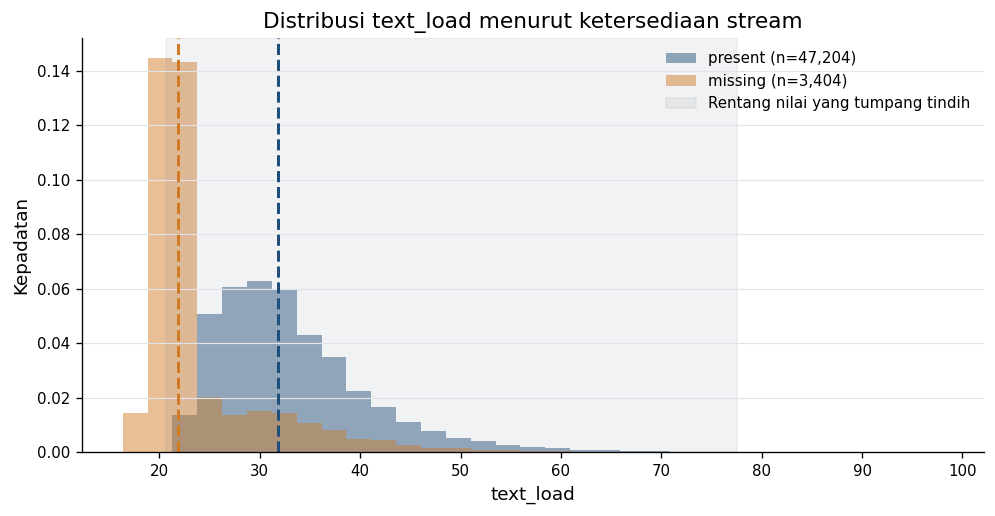

Median text_load adalah **31.78** saat stream tersedia dan **21.81** saat missing. Rentang nilai yang sama-sama teramati adalah **20.65–77.52**; di luarnya terdapat 906 baris missing dan 65 baris present.

In [8]:
eda_text_summary = eda_analysis.groupby('availability')['text_load'].agg(n='size', minimum='min', q1=lambda eda_x: eda_x.quantile(0.25), median='median', q3=lambda eda_x: eda_x.quantile(0.75), maximum='max').loc[['present', 'missing']]
eda_overlap_low = max(eda_text_summary.loc['present', 'minimum'], eda_text_summary.loc['missing', 'minimum'])
eda_overlap_high = min(eda_text_summary.loc['present', 'maximum'], eda_text_summary.loc['missing', 'maximum'])
eda_outside_missing = int((eda_analysis.availability.eq('missing') & ~eda_analysis.text_load.between(eda_overlap_low, eda_overlap_high)).sum())
eda_outside_present = int((eda_analysis.availability.eq('present') & ~eda_analysis.text_load.between(eda_overlap_low, eda_overlap_high)).sum())
display(eda_text_summary.round(2))
eda_fig, eda_ax = plt.subplots(figsize=(8.4, 4.4))
eda_bins = np.linspace(eda_analysis.text_load.min(), eda_analysis.text_load.max(), 34)
for eda_availability in ('present', 'missing'):
    eda_values = eda_analysis.loc[eda_analysis.availability.eq(eda_availability), 'text_load']
    eda_ax.hist(eda_values, bins=eda_bins, density=True, alpha=0.48, color=eda_COLORS[eda_availability], label=f'{eda_availability} (n={len(eda_values):,})')
    eda_ax.axvline(eda_values.median(), color=eda_COLORS[eda_availability], lw=1.8, linestyle='--')
eda_ax.axvspan(eda_overlap_low, eda_overlap_high, color='#78828f', alpha=0.1, label='Rentang nilai yang tumpang tindih')
eda_ax.set_xlabel('text_load')
eda_ax.set_ylabel('Kepadatan')
eda_ax.set_title('Distribusi text_load menurut ketersediaan stream')
eda_ax.legend(frameon=False)
eda_ax.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_fig.tight_layout()
plt.show()
display(Markdown(f"Median text_load adalah **{eda_text_summary.loc['present', 'median']:.2f}** saat stream tersedia dan **{eda_text_summary.loc['missing', 'median']:.2f}** saat missing. Rentang nilai yang sama-sama teramati adalah **{eda_overlap_low:.2f}–{eda_overlap_high:.2f}**; di luarnya terdapat {eda_outside_missing:,} baris missing dan {eda_outside_present:,} baris present."))

**Insight volume.** Median `text_load` kelompok kosong 21,81, sedangkan kelompok terisi 31,78. Komposisi volume yang berbeda menjadi alasan untuk membandingkan kelompok waktu/volume yang lebih setara.

### EDA 6. Menyamakan komposisi

Bandingkan hasil awal dengan penyesuaian setiap cycle serta tiga periode x 5/10 kelompok volume. **Gap = persentase kosong - terisi**, dalam poin persentase (pp). Coverage menunjukkan bagian data yang memenuhi minimum support.

In [9]:
eda_cycle_standardized, eda_cycle_cells = standardized_contrast(eda_analysis, ['cycle_code'], min_support=20)
eda_q5_frame, eda_q5_edges = add_global_quantile_bins(eda_analysis, 5)
eda_period_q5, eda_period_q5_cells = standardized_contrast(eda_q5_frame, ['period', 'text_load_q5'], min_support=20)
eda_q10_frame, eda_q10_edges = add_global_quantile_bins(eda_analysis, 10)
eda_period_q10, eda_period_q10_cells = standardized_contrast(eda_q10_frame, ['period', 'text_load_q10'], min_support=20)
eda_comparison_rows = [{'Kontras': 'Marginal (seluruh Train)', 'Present (%)': eda_marginal_indexed.loc['present', 'Proporsi (%)'], 'Missing (%)': eda_marginal_indexed.loc['missing', 'Proporsi (%)'], 'Gap missing − present (pp)': eda_marginal_gap_pp, 'Sel didukung': '—', 'Baris present tercakup': int(eda_analysis.availability.eq('present').sum()), 'Baris missing tercakup': int(eda_analysis.availability.eq('missing').sum()), 'Coverage keseluruhan (%)': 100.0}]
for eda_label, eda_result in [('Exact cycle', eda_cycle_standardized), ('Periode × kuantil text_load (5)', eda_period_q5), ('Periode × kuantil text_load (10)', eda_period_q10)]:
    eda_comparison_rows.append({'Kontras': eda_label, 'Present (%)': 100 * eda_result['standardized_prevalence']['present'], 'Missing (%)': 100 * eda_result['standardized_prevalence']['missing'], 'Gap missing − present (pp)': eda_result['standardized_missing_minus_present_pp'], 'Sel didukung': f"{eda_result['cells_supported']}/{eda_result['cells_total']}", 'Baris present tercakup': eda_result['covered_rows_by_availability']['present'], 'Baris missing tercakup': eda_result['covered_rows_by_availability']['missing'], 'Coverage keseluruhan (%)': 100 * eda_result['coverage_all_rows']})
eda_contrasts = pd.DataFrame(eda_comparison_rows)
display(eda_contrasts.round(2))
eda_support_by_group = pd.DataFrame([{'Kontras': 'Exact cycle', 'Coverage present (%)': 100 * eda_cycle_standardized['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_cycle_standardized['coverage_by_availability']['missing']}, {'Kontras': 'Periode × kuantil 5', 'Coverage present (%)': 100 * eda_period_q5['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_period_q5['coverage_by_availability']['missing']}, {'Kontras': 'Periode × kuantil 10', 'Coverage present (%)': 100 * eda_period_q10['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_period_q10['coverage_by_availability']['missing']}])
display(eda_support_by_group.round(2))
print(f'Minimum support: 20 baris per availability per sel. Jumlah interval kuantil: 5-bin={len(eda_q5_edges) - 1}; 10-bin={len(eda_q10_edges) - 1}.')

,Kontras,Present (%),Missing (%),Gap missing − present (pp),Sel didukung,Baris present tercakup,Baris missing tercakup,Coverage keseluruhan (%)
0,Marginal (seluruh Train),34.47,38.13,3.66,—,47204,3404,100.00
1,Exact cycle,34.47,38.43,3.96,33/33,47204,3404,100.00
2,Periode × kuantil text_load (5),35.17,32.87,-2.30,15/15,47204,3404,100.00
3,Periode × kuantil text_load (10),35.52,33.36,-2.15,28/30,44368,3372,94.33


,Kontras,Coverage present (%),Coverage missing (%)
0,Exact cycle,100.00,100.00
1,Periode × kuantil 5,100.00,100.00
2,Periode × kuantil 10,93.99,99.06


Minimum support: 20 baris per availability per sel. Jumlah interval kuantil: 5-bin=5; 10-bin=10.


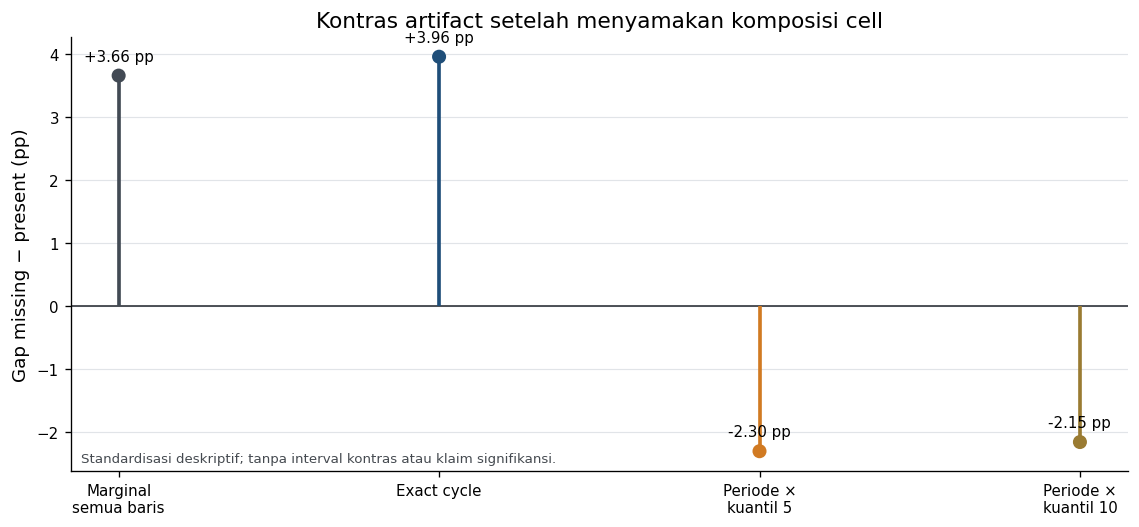

In [10]:
eda_fig, eda_ax = plt.subplots(figsize=(9.6, 4.5))
eda_labels = ['Marginal\nsemua baris', 'Exact cycle', 'Periode ×\nkuantil 5', 'Periode ×\nkuantil 10']
eda_gaps = eda_contrasts['Gap missing − present (pp)'].to_numpy()
eda_colors = ['#424a54', '#1f4e79', '#d17a22', '#9a7b32']
eda_x = np.arange(len(eda_gaps))
eda_ax.axhline(0, color='#30343b', lw=1)
eda_ax.vlines(eda_x, 0, eda_gaps, color=eda_colors, lw=2.2)
eda_ax.scatter(eda_x, eda_gaps, color=eda_colors, s=55, zorder=3)
for eda_i, eda_row in eda_contrasts.iterrows():
    eda_value = eda_row['Gap missing − present (pp)']
    eda_ax.annotate(f'{eda_value:+.2f} pp', (eda_i, eda_value), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=9)
eda_ax.set_xticks(eda_x, eda_labels)
eda_ax.set_ylabel('Gap missing − present (pp)')
eda_ax.set_title('Kontras artifact setelah menyamakan komposisi cell')
eda_ax.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_ax.text(0.01, 0.02, 'Standardisasi deskriptif; tanpa interval kontras atau klaim signifikansi.', transform=eda_ax.transAxes, fontsize=8, color='#454a50')
eda_fig.tight_layout()
plt.show()

**Insight penyesuaian.** Menyamakan cycle saja tidak membalik arah gap, sedangkan penyesuaian periode dan volume membalikkannya. Hasil 5 dan 10 kelompok memiliki arah serupa, dengan coverage lebih rendah pada 10 kelompok.

### EDA 7. Interpretasi dan batasan

In [11]:
display(Markdown(
    f"**Hasil:** gap awal {eda_marginal_gap_pp:+.2f} pp; setelah penyesuaian cycle "
    f"{eda_cycle_standardized['standardized_missing_minus_present_pp']:+.2f} pp; "
    f"periode x volume: {eda_period_q5['standardized_missing_minus_present_pp']:+.2f} pp (5 kelompok), "
    f"{eda_period_q10['standardized_missing_minus_present_pp']:+.2f} pp (10 kelompok).\n\n"
    f"**Dukungan:** minimum 20 baris per status/kelompok. Coverage 10 kelompok "
    f"{eda_period_q10['supported_rows_total']:,}/{len(eda_analysis):,} "
    f"({eda_period_q10['coverage_all_rows']:.2%}); "
    f"{eda_period_q10['cells_supported']}/{eda_period_q10['cells_total']} kelompok didukung.\n\n"
    "**Batasan:** kelompok volume masih kasar; faktor lain belum dikontrol. "
    "Hasil bukan sebab-akibat atau konfirmasi independen. Routing berasal dari diagnosis model terdahulu, "
    "bukan ditemukan secara prospektif melalui EDA ini."
))

**Hasil:** gap awal +3.66 pp; setelah penyesuaian cycle +3.96 pp; periode x volume: -2.30 pp (5 kelompok), -2.15 pp (10 kelompok).

**Dukungan:** minimum 20 baris per status/kelompok. Coverage 10 kelompok 47,740/50,608 (94.33%); 28/30 kelompok didukung.

**Batasan:** kelompok volume masih kasar; faktor lain belum dikontrol. Hasil bukan sebab-akibat atau konfirmasi independen. Routing berasal dari diagnosis model terdahulu, bukan ditemukan secara prospektif melalui EDA ini.

### EDA 8. Kesimpulan

Persentase label 1 pada teks kosong lebih tinggi secara keseluruhan (**38,13% vs 34,47%**). Setelah waktu dan volume diperhitungkan, selisih berbalik menjadi sekitar **-2,2 sampai -2,3 pp**. Jadi, perbandingan dipengaruhi komposisi laporan.

Ini hubungan deskriptif, bukan sebab-akibat. Kelompok volume masih kasar; pemeriksaan 10 kelompok mencakup **94,33%** baris. Pola official Test belum diketahui.

## 4. Perkembangan pendekatan

1. Majority dan model sederhana sebagai baseline.
2. LR/HGB dengan fitur terstruktur.
3. TF-IDF dan hybrid C2_B untuk menambah informasi teks.
4. C4_HGB mengatasi kelemahan hybrid saat teks kosong melalui routing.

Tabel berikut berasal dari eksperimen historis terverifikasi. Primary menggabungkan enam window; H12 menguji horizon lebih panjang dengan sebagian baris yang sama, sehingga bukan bukti independen. TF-IDF memakai unigram-bigram, maksimal 20.000 fitur, `min_df=3`, dan sublinear TF.

,metode,Primary Macro F1,H12 Macro F1
recipe,,,
C0_A,Majority,0.38938,0.38938
C0_C,LR impact + EF,0.38938,0.38938
C1_A,LR structured,0.71453,0.67679
C1_B,HGB structured,0.73102,0.68906
C2_A,TF-IDF LR,0.80139,0.78192
C2_B,Hybrid LR,0.82063,0.78858
C4_HGB,Hybrid + HGB availability routing,0.82548,0.79681


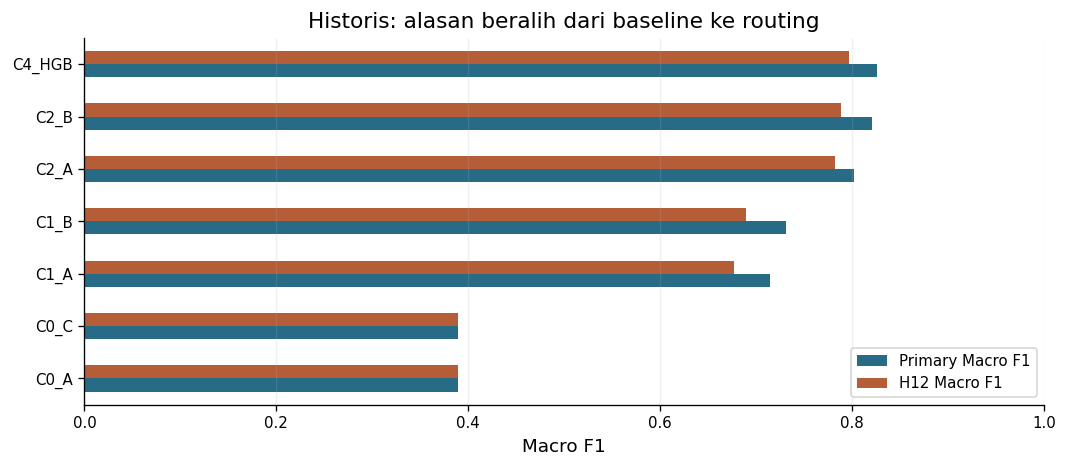

policy             fixed_0.5  inner_pooled
recipe keluarga                           
C2_B   H12 pooled     0.7886        0.7924
       Primary        0.8206        0.8188
C4_HGB H12 pooled     0.7968        0.7998
       Primary        0.8255        0.8236

,primary Macro F1,H12 Macro F1,primary stream-present F1,primary stream-missing F1,H12 stream-present F1,H12 stream-missing F1
recipe,,,,,,
C2_B,0.8206,0.7886,0.8286,0.7104,0.8005,0.6305
C4_LR,0.8242,0.7945,0.8286,0.7596,0.8005,0.7085
C4_HGB,0.8255,0.7968,0.8286,0.7817,0.8005,0.7450


In [12]:
def load_verified_history(round_name):
    folder = PROJECT_ROOT / f"reports/classification_{round_name}"
    result = json.loads((folder / "results.json").read_text(encoding="utf-8"))
    verification = json.loads((folder / "verification.json").read_text(encoding="utf-8"))
    assert verification["status"] == "PASS", f"{round_name} verification is not PASS"
    assert result["freeze_signature"] == verification["freeze_signature"]
    return result, verification

history_r1, verify_r1 = load_verified_history("round1")
history_r2, verify_r2 = load_verified_history("round2")

r1_primary = history_r1["aggregate"]["primary"]["fixed_0.5"]
r1_h12 = history_r1["aggregate"]["secondary"]["fixed_0.5"]
r2_primary = history_r2["aggregate"]["primary"]["fixed_0.5"]
r2_h12 = history_r2["aggregate"]["secondary"]["fixed_0.5"]
names = {"C0_A":"Majority", "C0_C":"LR impact + EF", "C1_A":"LR structured",
         "C1_B":"HGB structured", "C2_A":"TF-IDF LR", "C2_B":"Hybrid LR"}
evolution_rows=[]
for recipe, label in names.items():
    evolution_rows.append({"recipe":recipe,"metode":label,
        "Primary Macro F1":r1_primary[recipe]["metrics"]["macro_f1"],
        "H12 Macro F1":r1_h12[recipe]["metrics"]["macro_f1"]})
evolution_rows.append({"recipe":"C4_HGB","metode":"Hybrid + HGB availability routing",
    "Primary Macro F1":r2_primary["C4_HGB"]["metrics"]["macro_f1"],
    "H12 Macro F1":r2_h12["C4_HGB"]["metrics"]["macro_f1"]})
evolution = pd.DataFrame(evolution_rows).set_index("recipe")
display(evolution.round(5))
ax=evolution[["Primary Macro F1","H12 Macro F1"]].plot.barh(color=["#276b86","#b45d36"],figsize=(9,4))
ax.set(title="Historis: alasan beralih dari baseline ke routing", xlabel="Macro F1", xlim=(0,1),ylabel="")
ax.legend(fontsize=9);ax.grid(axis="x",alpha=.2);plt.tight_layout();plt.show()

threshold_rows = []
for family, key in [("Primary", "primary"), ("H12 pooled", "secondary")]:
    for policy in ["fixed_0.5", "inner_pooled"]:
        cell = history_r2["aggregate"][key][policy]["C2_B"]
        threshold_rows.append({"recipe": "C2_B", "keluarga": family, "policy": policy,
                               "Macro F1": cell["metrics"]["macro_f1"]})
        route = history_r2["aggregate"][key][policy]["C4_HGB"]
        threshold_rows.append({"recipe": "C4_HGB", "keluarga": family, "policy": policy,
                               "Macro F1": route["metrics"]["macro_f1"]})
display(pd.DataFrame(threshold_rows).pivot_table(index=["recipe", "keluarga"], columns="policy",
                                                 values="Macro F1").round(4))

route_comparison = []
for recipe in ["C2_B", "C4_LR", "C4_HGB"]:
    primary = r2_primary[recipe]
    h12 = r2_h12[recipe]
    route_comparison.append({
        "recipe": recipe,
        "primary Macro F1": primary["metrics"]["macro_f1"],
        "H12 Macro F1": h12["metrics"]["macro_f1"],
        "primary stream-present F1": primary["subgroups"]["stream_present"]["macro_f1"],
        "primary stream-missing F1": primary["subgroups"]["stream_missing"]["macro_f1"],
        "H12 stream-present F1": h12["subgroups"]["stream_present"]["macro_f1"],
        "H12 stream-missing F1": h12["subgroups"]["stream_missing"]["macro_f1"],
    })
display(pd.DataFrame(route_comparison).set_index("recipe").round(4))

**Insight pemilihan model.** C4_HGB mencapai Macro F1 **0,8255 primary / 0,7968 H12**, dibanding C2_B **0,8206 / 0,7886**. Threshold inner dan perubahan bobot fitur tidak memberi perbaikan konsisten.

## 5. Pipeline dan validasi temporal

Fit pada cycle 47-75, evaluasi 76-79. C2_B adalah hybrid Logistic Regression; C1_B adalah structured HGB. Threshold tetap 0,50, tidak dipilih dari label evaluasi.

In [13]:
# Siklus terakhir sebagai contoh temporal end-to-end; label validation tidak masuk ke fit.
FIT_CYCLES = (47, 75)
VALID_CYCLES = (76, 79)
protocol_r1 = json.loads((PROJECT_ROOT / "experiments/classification_round1/protocol.json").read_text(encoding="utf-8"))
feature_sets = protocol_r1["feature_sets"]
X_STRUCTURED = list(feature_sets["structured"])
X_HYBRID = list(feature_sets["hybrid"])

fit_mask = train.cycle_code.between(*FIT_CYCLES)
valid_mask = train.cycle_code.between(*VALID_CYCLES)
fit_rows = np.flatnonzero(fit_mask.to_numpy())
valid_rows = np.flatnonzero(valid_mask.to_numpy())
assert len(np.intersect1d(fit_rows, valid_rows)) == 0
assert int(train.loc[fit_mask, "cycle_code"].max()) < int(train.loc[valid_mask, "cycle_code"].min())
assert train.loc[fit_mask, "artifact_signal"].nunique() == 2

X_fit_hybrid = train.loc[fit_mask, X_HYBRID].copy()
X_fit_structured = train.loc[fit_mask, X_STRUCTURED].copy()
y_fit = train.loc[fit_mask, "artifact_signal"].to_numpy(dtype=np.int8, copy=True)
X_valid_hybrid = train.loc[valid_mask, X_HYBRID].copy()
X_valid_structured = train.loc[valid_mask, X_STRUCTURED].copy()

c2b = build_round2_model({"id": "C2_B", "kind": "control", "source": "C2_B"})
c1b = build_round2_model({"id": "C1_B", "kind": "control", "source": "C1_B"})
with threadpool_limits(limits=2):
    c2b.fit(X_fit_hybrid, y_fit)
    probability_c2b = c2b.predict_proba(X_valid_hybrid)
    c1b.fit(X_fit_structured, y_fit)
    probability_c1b = c1b.predict_proba(X_valid_structured)

missing_valid = stream_missing_mask(X_valid_hybrid)
probability_c4hgb = np.where(missing_valid, probability_c1b, probability_c2b)
threshold = 0.50

# Open validation labels only after both fitted models have produced probabilities.
y_valid = train.loc[valid_mask, "artifact_signal"].to_numpy(dtype=np.int8, copy=True)
validation_cycles = train.loc[valid_mask, "cycle_code"].to_numpy(copy=True)
probabilities = {"C1_B": probability_c1b, "C2_B": probability_c2b, "C4_HGB": probability_c4hgb}
assert all(np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all() for p in probabilities.values())
assert len(y_valid) == len(valid_rows) == 8491
assert (int(train.loc[fit_mask].shape[0]), int(train.loc[fit_mask, "cycle_code"].min()),
        int(train.loc[fit_mask, "cycle_code"].max())) == (42117, 47, 75)
print(f"Fit: {len(fit_rows):,} rows, cycles {FIT_CYCLES[0]}–{FIT_CYCLES[1]}")
print(f"Validation: {len(valid_rows):,} rows, cycles {VALID_CYCLES[0]}–{VALID_CYCLES[1]}")
print(f"signal_stream kosong di validation: {int(missing_valid.sum()):,} ({missing_valid.mean():.2%})")
print("Threshold untuk seluruh hasil utama:", threshold)

Fit: 42,117 rows, cycles 47–75
Validation: 8,491 rows, cycles 76–79
signal_stream kosong di validation: 526 (6.19%)
Threshold untuk seluruh hasil utama: 0.5


### Pemeriksaan reproduksi

Imputasi, encoding, scaling, dan TF-IDF dipelajari di dalam fit. Hash prediksi dibandingkan dengan receipt historis W6 tanpa cache model pribadi.

In [14]:
round1_fit75 = json.loads((PROJECT_ROOT / "reports/classification_round1/fit_audits/fit75.json").read_text(encoding="utf-8"))
round2_results = history_r2
round2_w6 = {
    job["model"]: job for job in round2_results["jobs"]
    if job.get("window") == "W6" and job.get("model") in {"C1_B", "C2_B", "C4_HGB"}
}
probability_hashes = {
    "C1_B": _array_digest(probability_c1b),
    "C2_B": _array_digest(probability_c2b),
    "C4_HGB": _array_digest(probability_c4hgb),
}
expected_hashes = {
    "C1_B": round1_fit75["C1_B"]["probability_sha256"],
    "C2_B": round1_fit75["C2_B"]["probability_sha256"],
    "C4_HGB": round2_w6["C4_HGB"]["probability_sha256"],
}
hash_checks = pd.DataFrame([
    {"model": name, "refit W6 probability SHA-256": probability_hashes[name],
     "verified historical SHA-256": expected_hashes[name],
     "identik": probability_hashes[name] == expected_hashes[name]}
    for name in probabilities
])
display(hash_checks[["model", "identik"]])
assert hash_checks["identik"].all(), "Fresh W6 predictions differ from the verified historical recipe."

audit_rows = []
for name, model in [("C2_B", c2b), ("C1_B", c1b)]:
    state = model.audit_state()
    audit_rows.append({"model": name, "fit rows": state["fit_rows"],
                       "input features": len(state["input_feature_names"]),
                       "state SHA-256": state.get("model_state_sha256", state.get("fit_fingerprint")),
                       "preprocessing fit-only": True})
display(pd.DataFrame(audit_rows))

,model,identik
0,C1_B,True
1,C2_B,True
2,C4_HGB,True


,model,fit rows,input features,state SHA-256,preprocessing fit-only
0,C2_B,42117,13,b2516813479876fb95457791ceab58b51fc2b58b60b84e...,True
1,C1_B,42117,12,f7b99ab8b68265b609eb9d13f24c9d59a77076b03c96b2...,True


## 6. Evaluasi model

Confusion matrix: baris aktual, kolom prediksi. Periksa precision dan recall bersama Macro F1.

,n,Macro F1,F1 kelas 0,F1 kelas 1,AP,positive aktual,positive prediksi
model,,,,,,,
C1_B,8491,0.7037,0.8368,0.5706,0.6376,0.2944,0.2563
C2_B,8491,0.8056,0.8886,0.7226,0.7756,0.2944,0.2786
C4_HGB,8491,0.8104,0.8940,0.7268,0.7809,0.2944,0.2646


,model,kelas,support,precision,recall,F1
0,C1_B,0,5991,0.8154,0.8595,0.8368
1,C1_B,1,2500,0.6131,0.5336,0.5706
2,C2_B,0,5991,0.8789,0.8985,0.8886
3,C2_B,1,2500,0.7430,0.7032,0.7226
4,C4_HGB,0,5991,0.8759,0.9129,0.8940
5,C4_HGB,1,2500,0.7677,0.6900,0.7268


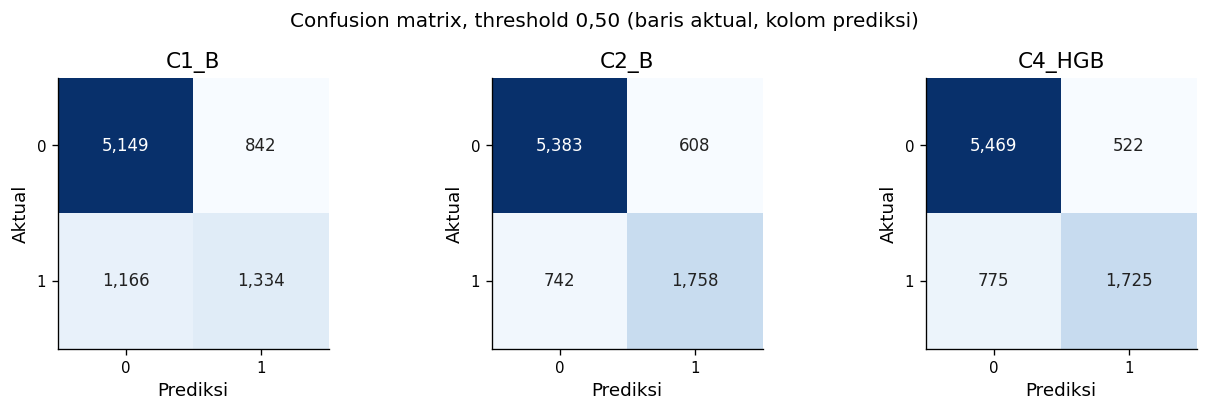

model,C1_B,C2_B,C4_HGB
cycle,,,
76,0.7273,0.7937,0.7968
77,0.7268,0.7916,0.8014
78,0.6773,0.8115,0.8175
79,0.6762,0.8214,0.8213


,equal-cycle Macro F1
model,
C1_B,0.7019
C2_B,0.8046
C4_HGB,0.8093


In [15]:
def one_row_metrics(name, mask=None):
    if mask is None:
        mask = np.ones(len(y_valid), dtype=bool)
    result = binary_metrics(y_valid[mask], probabilities[name][mask], threshold)
    return result

metric_results = {name: one_row_metrics(name) for name in probabilities}
overall_rows = []
class_rows = []
for name, result in metric_results.items():
    m = result
    overall_rows.append({"model": name, "n": m["n"], "Macro F1": m["macro_f1"],
                         "F1 kelas 0": m["per_class"][0]["f1"], "F1 kelas 1": m["per_class"][1]["f1"],
                         "AP": m["average_precision"], "positive aktual": m["positive_rate"],
                         "positive prediksi": m["positive_prediction_rate"]})
    for cls in m["per_class"]:
        class_rows.append({"model": name, "kelas": cls["label"], "support": cls["support"],
                           "precision": cls["precision"], "recall": cls["recall"], "F1": cls["f1"]})
overall_table = pd.DataFrame(overall_rows).set_index("model")
display(overall_table.style.format("{:.4f}", subset=["Macro F1", "F1 kelas 0", "F1 kelas 1", "AP", "positive aktual", "positive prediksi"]))
display(pd.DataFrame(class_rows).style.format({"precision": "{:.4f}", "recall": "{:.4f}", "F1": "{:.4f}"}))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (name, result) in zip(axes, metric_results.items()):
    cm = np.asarray(result["confusion_matrix"])
    ax.imshow(cm, cmap="Blues")
    ax.set(title=name, xlabel="Prediksi", ylabel="Aktual", xticks=[0, 1], yticks=[0, 1])
    for (i, j), value in np.ndenumerate(cm):
        ax.text(j, i, f"{value:,}", ha="center", va="center",
                color="white" if value > cm.max() * 0.55 else "#222222")
fig.suptitle("Confusion matrix, threshold 0,50 (baris aktual, kolom prediksi)")
plt.tight_layout()
plt.show()

cycle_rows = []
for name, p in probabilities.items():
    for cycle in sorted(np.unique(validation_cycles)):
        mask = validation_cycles == cycle
        m = binary_metrics(y_valid[mask], p[mask], threshold)
        cycle_rows.append({"model": name, "cycle": int(cycle), "n": int(mask.sum()),
                           "Macro F1": m["macro_f1"], "prevalence": m["positive_rate"],
                           "positive prediksi": m["positive_prediction_rate"]})
cycle_table = pd.DataFrame(cycle_rows)
display(cycle_table.pivot(index="cycle", columns="model", values="Macro F1").round(4))
equal_cycle = cycle_table.groupby("model")["Macro F1"].mean().rename("equal-cycle Macro F1")
display(equal_cycle.to_frame().round(4))

**Insight W6.** Routing mengurangi false positive dari **608 menjadi 522**, tetapi true positive juga turun dari **1.758 menjadi 1.725** dibanding hybrid C2_B. Jadi, peningkatan keputusan memiliki trade-off: lebih sedikit alarm salah dengan sedikit kehilangan deteksi positif.

model,C1_B,C2_B,C4_HGB
kelompok,,,
EF0,0.6715,0.8033,0.8078
EF1,0.7354,0.7970,0.8011
stream kosong,0.7466,0.6775,0.7466
stream tersedia,0.7007,0.8147,0.8147


,kelompok,model,n,Macro F1,F1 kelas 0,F1 kelas 1,FP,FN
0,stream kosong,C1_B,526,0.7466,0.8502,0.6431,40,71
1,stream kosong,C2_B,526,0.6775,0.7363,0.6186,126,38
2,stream kosong,C4_HGB,526,0.7466,0.8502,0.6431,40,71
3,stream tersedia,C1_B,7965,0.7007,0.8360,0.5654,802,1095
4,stream tersedia,C2_B,7965,0.8147,0.8968,0.7326,482,704
5,stream tersedia,C4_HGB,7965,0.8147,0.8968,0.7326,482,704


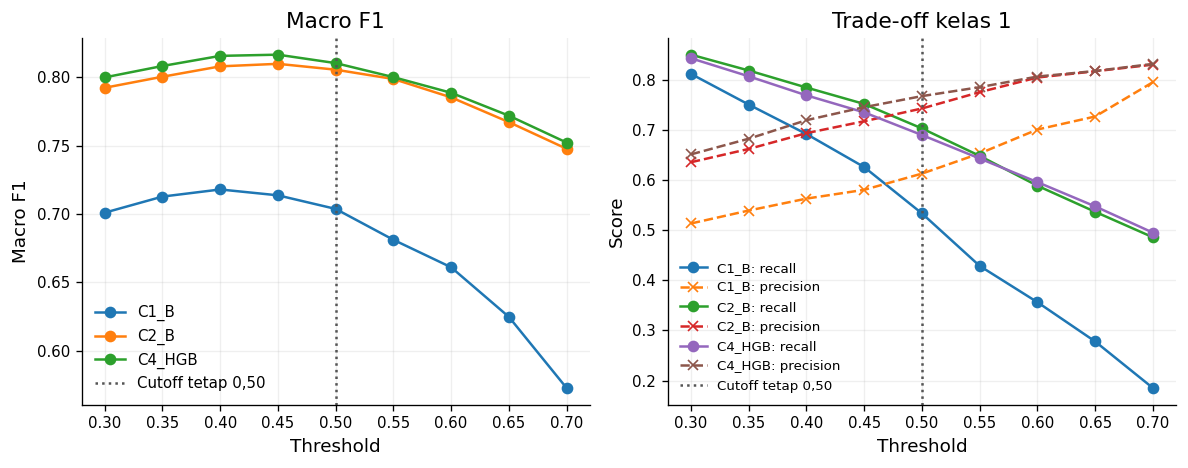

,model,threshold,Macro F1,precision class 1,recall class 1,positive prediction rate
4,C1_B,0.5,0.7037,0.6131,0.5336,0.2563
13,C2_B,0.5,0.8056,0.7430,0.7032,0.2786
22,C4_HGB,0.5,0.8104,0.7677,0.6900,0.2646


In [16]:
subgroup_masks = {
    "stream kosong": missing_valid,
    "stream tersedia": ~missing_valid,
    "EF0": train.loc[valid_mask, "entry_friction"].eq(0).to_numpy(),
    "EF1": train.loc[valid_mask, "entry_friction"].eq(1).to_numpy(),
}
subgroup_rows = []
for group, mask in subgroup_masks.items():
    for name, p in probabilities.items():
        m = binary_metrics(y_valid[mask], p[mask], threshold)
        subgroup_rows.append({"kelompok": group, "model": name, "n": m["n"],
                              "Macro F1": m["macro_f1"], "F1 kelas 0": m["per_class"][0]["f1"],
                              "F1 kelas 1": m["per_class"][1]["f1"],
                              "FP": m["false_positive"], "FN": m["false_negative"]})
subgroup_table = pd.DataFrame(subgroup_rows)
display(subgroup_table.pivot(index="kelompok", columns="model", values="Macro F1").round(4))
display(subgroup_table[subgroup_table["kelompok"].str.startswith("stream")].round(4))

# Descriptive cutoff sensitivity on the same temporal validation block.
# This grid is not used to choose or replace the frozen 0.50 threshold.
threshold_rows = []
cutoff_grid = np.round(np.arange(0.30, 0.701, 0.05), 2)
for name, p in probabilities.items():
    for cutoff in cutoff_grid:
        m = binary_metrics(y_valid, p, float(cutoff))
        threshold_rows.append({"model": name, "threshold": cutoff, "Macro F1": m["macro_f1"],
                               "precision class 1": m["per_class"][1]["precision"],
                               "recall class 1": m["per_class"][1]["recall"],
                               "positive prediction rate": m["positive_prediction_rate"]})
threshold_table = pd.DataFrame(threshold_rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for name, group in threshold_table.groupby("model"):
    axes[0].plot(group.threshold, group["Macro F1"], marker="o", label=name)
    axes[1].plot(group.threshold, group["recall class 1"], marker="o", label=f"{name}: recall")
    axes[1].plot(group.threshold, group["precision class 1"], marker="x", linestyle="--", label=f"{name}: precision")
for ax in axes:
    ax.axvline(0.50, color="#555555", linestyle=":", label="Cutoff tetap 0,50")
    ax.set_xlabel("Threshold")
    ax.grid(alpha=0.2)
axes[0].set(title="Macro F1", ylabel="Macro F1")
axes[1].set(title="Trade-off kelas 1", ylabel="Score")
axes[0].legend(frameon=False)
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
display(threshold_table[threshold_table.threshold.eq(0.50)].round(4))

Kurva threshold hanya diagnostik; keputusan tetap **0,50**.

### Recipe individual dan Kaggle

- Teks kosong: C1_B structured HGB.
- Teks terisi: C2_B structured + TF-IDF LR.
- Routing hanya memakai ketersediaan fitur; ID dan target tidak menjadi predictor.

Skor public di bawah berasal dari manifest submission historis, terpisah dari validasi temporal.

In [17]:
submission_manifest = json.loads(
    (PROJECT_ROOT / "reports/submissions/classification_initial_manifest.json").read_text(encoding="utf-8")
)
kaggle = submission_manifest["kaggle_submission"]
assert submission_manifest["task"] == "classification"
assert kaggle["status"] == "COMPLETE"
assert kaggle["reference"] == 57808225
assert float(kaggle["public_score"]) == 0.82641
candidate_id = "C4_HGB"
assert candidate_id in submission_manifest["model"]["route"]
assert float(submission_manifest["model"]["threshold"]) == 0.50
display(pd.DataFrame([{
    "kandidat": candidate_id,
    "threshold": submission_manifest["model"]["threshold"],
    "status Kaggle": kaggle["status"],
    "public score": kaggle["public_score"],
    "submission ref": kaggle["reference"],
    "private score tersedia": kaggle["private_score"] is not None,
}]))

historical_w6 = pd.DataFrame([
    {"model": name, "W6 probability SHA-256": round2_w6[name]["probability_sha256"],
     "Macro F1": round2_w6[name]["policies"]["fixed_0.5"]["metrics"]["macro_f1"]}
    for name in ["C1_B", "C2_B", "C4_HGB"]
])
fresh_w6 = pd.DataFrame([
    {"model": name, "fresh SHA-256": probability_hashes[name],
     "fresh Macro F1": metric_results[name]["macro_f1"]}
    for name in ["C1_B", "C2_B", "C4_HGB"]
])
display(historical_w6.merge(fresh_w6, on="model").round(6))

,kandidat,threshold,status Kaggle,public score,submission ref,private score tersedia
0,C4_HGB,0.5,COMPLETE,0.82641,57808225,False


,model,W6 probability SHA-256,Macro F1,fresh SHA-256,fresh Macro F1
0,C1_B,a21ba8ffa0396afe9f8d7ee78bbcccc5d6024ade0037f1...,0.703700,a21ba8ffa0396afe9f8d7ee78bbcccc5d6024ade0037f1...,0.703700
1,C2_B,01a886bb391728b58cb3504946d620efabc4859ea55585...,0.805571,01a886bb391728b58cb3504946d620efabc4859ea55585...,0.805571
2,C4_HGB,fc83ef0c5be271e1f952c24e9d196f85144ada3c701a1c...,0.810384,fc83ef0c5be271e1f952c24e9d196f85144ada3c701a1c...,0.810384


In [18]:
core_receipt={'task':'classification','fit_cycles':[47,75],'validation_cycles':[76,79],
    'fit_rows':len(fit_rows),'validation_rows':len(valid_rows),'threshold':0.5,
    'metrics':{name:float(result['macro_f1']) for name,result in metric_results.items()},
    'probability_sha256':probability_hashes,'matches_historical_predictions':True,
    'historical_primary_macro_f1':float(r2_primary['C4_HGB']['metrics']['macro_f1']),
    'historical_h12_macro_f1':float(r2_h12['C4_HGB']['metrics']['macro_f1']),
    'kaggle_public_macro_f1':0.82641,'fit_preprocessing_only_train':True,'test_used_in_core':False}
receipt_path=PROJECT_ROOT/'artifacts/samuel_eda_final_review/classification_core_receipt.json'
receipt_path.parent.mkdir(parents=True,exist_ok=True)
receipt_path.write_text(json.dumps(core_receipt,indent=2)+'\n',encoding='utf-8')

820

## 7. Refit penuh (opsional)

Dimatikan secara default. Jika diaktifkan, pipeline dilatih pada seluruh Train dan menulis CSV lokal; tidak mengunggah ke Kaggle.

In [19]:
RUN_FULL_TRAIN_INFERENCE = False
if RUN_FULL_TRAIN_INFERENCE:
    if DATA_FILES["test"] is None or DATA_FILES["sample"] is None:
        raise FileNotFoundError("Official Test.csv dan SampleSubmission.csv diperlukan untuk inference.")
    assert sha256_file(DATA_FILES['test']) == '4e6c381d582ed24f92d17f620f4f0ad25e2e0def29eb57a91a5482867f6afe3c'
    assert sha256_file(DATA_FILES['sample']) == '889f97d69659a64945421d841dcf96e5813020606f29b2992d4b9560cecdcba7'
    test = pd.read_csv(DATA_FILES["test"])
    sample = pd.read_csv(DATA_FILES["sample"])
    assert list(sample.columns) == ["record_id", "artifact_signal"]
    assert len(test) == len(sample) == 29_421
    assert test["record_id"].is_unique and sample["record_id"].is_unique
    assert test["record_id"].tolist() == sample["record_id"].tolist()
    assert 'artifact_signal' not in test and set(test.columns) == set(train.columns) - {'artifact_signal'}
    assert not set(train.record_id) & set(test.record_id) and test.cycle_code.between(80,91).all()
    assert set(X_HYBRID).issubset(test.columns) and set(X_STRUCTURED).issubset(test.columns)

    full_X_hybrid = train.loc[:, X_HYBRID].copy()
    full_X_structured = train.loc[:, X_STRUCTURED].copy()
    full_y = train["artifact_signal"].to_numpy(dtype=np.int8, copy=True)
    full_c2b = build_round2_model({"id": "C2_B", "kind": "control", "source": "C2_B"})
    full_c1b = build_round2_model({"id": "C1_B", "kind": "control", "source": "C1_B"})
    with threadpool_limits(limits=2):
        full_c2b.fit(full_X_hybrid, full_y)
        test_p_c2b = full_c2b.predict_proba(test.loc[:, X_HYBRID])
        full_c1b.fit(full_X_structured, full_y)
        test_p_c1b = full_c1b.predict_proba(test.loc[:, X_STRUCTURED])
    test_missing = stream_missing_mask(test[["signal_stream"]])
    test_prob = np.where(test_missing, test_p_c1b, test_p_c2b)
    test_prediction = (test_prob >= 0.50).astype(np.int8)
    assert len(test_prediction) == 29_421 and set(np.unique(test_prediction)).issubset({0, 1})
    submission_preview = pd.DataFrame({"record_id": sample["record_id"], "artifact_signal": test_prediction})
    assert submission_preview.columns.tolist() == sample.columns.tolist()
    assert submission_preview["record_id"].tolist() == sample["record_id"].tolist()
    assert submission_preview["artifact_signal"].notna().all()

    output_path = Path(os.environ.get(
        "SAMUEL_CLASSIFICATION_PREDICTION_PATH",
        PROJECT_ROOT / "artifacts/samuel_eda_final_review/classification_reproduced.csv",
    )).expanduser()
    if not output_path.is_absolute():
        output_path = PROJECT_ROOT / output_path
    output_path.parent.mkdir(parents=True, exist_ok=True)
    csv_bytes=submission_preview.to_csv(index=False).encode('utf-8')
    if output_path.exists() and output_path.read_bytes() != csv_bytes:
        raise FileExistsError('Output lokal sebelumnya berbeda; periksa sebelum menggantinya.')
    output_path.write_bytes(csv_bytes)
    print("CSV lokal dibuat; belum diunggah:", output_path.resolve())
    print("Jumlah baris:", len(submission_preview), "| class 1:", int(test_prediction.sum()))
else:
    print("Full-Train refit dan Test inference dilewati; tidak ada CSV submission yang dibuat.")

Full-Train refit dan Test inference dilewati; tidak ada CSV submission yang dibuat.


## 8. Kesimpulan

Teks menambah informasi prediktif, tetapi hybrid lebih lemah ketika teks kosong. Routing C4_HGB memberi **0,8255 primary / 0,7968 H12**; public benchmark approach ini **0,82641**.

EDA memberi konteks komposisi availability, bukan bukti bahwa missingness menyebabkan label atau bahwa EDA menyebabkan kenaikan skor. Window development sudah digunakan berulang; H12 bukan holdout independen dan public score tidak menjamin private score.

Petunjuk data, dependencies, dan bukti eksekusi: [README](README.md).